In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", None)

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATOS = RAIZ / "data" / "youtube_comments"

df = pd.read_csv(DATOS / "_OoWAqo4FSk_comments.csv", encoding="utf-8-sig")
sent = pd.read_csv(DATOS / "_OoWAqo4FSk_sentimiento.csv", encoding="utf-8-sig")

aux = df.loc[~df["es_respuesta"], ["id", "text"]].reset_index(drop=True).merge(sent, on="id")
aux.head()

Pipeline de limpieza: tokenización con NLTK (`TweetTokenizer`), lematización con spaCy (`es_core_news_sm`) y eliminación de stopwords en español de NLTK. spaCy lematiza el comentario completo para usar el contexto gramatical y después se quitan las stopwords, tanto por la palabra original como por su lema. Los nombres propios se conservan tal cual. Los emojis se extraen completos con la librería `emoji` antes de tokenizar, para no partir secuencias como ❤️, 🙋‍♀️ o 🇲🇽, y pasan intactos por todo el pipeline.

In [2]:
import re

import emoji
import nltk
import spacy
from nltk.corpus import stopwords
from nltk.tokenize import TweetTokenizer
from spacy.tokens import Doc

nltk.download("stopwords", quiet=True)

TOKENIZADOR = TweetTokenizer(preserve_case=True, reduce_len=True, strip_handles=True)
STOPWORDS = set(stopwords.words("spanish"))
nlp = spacy.load("es_core_news_sm", disable=["parser", "ner"])
PALABRA = re.compile(r"\w+(?:-\w+)*")


def normalizar_emoji(e):
    # quita el selector de variación para que ❤️ y ❤ cuenten como el mismo emoji
    return e.replace("\ufe0f", "")


def es_emoji(token):
    return emoji.is_emoji(token) or emoji.is_emoji(token + "\ufe0f")


def tokenizar(texto):
    """Tokeniza con NLTK los tramos de texto y conserva cada emoji como un token entero."""
    letras = [c for c in texto if c.isalpha()]
    if letras and sum(c.isupper() for c in letras) > 0.6 * len(letras):
        texto = texto.lower()  # comentarios en mayúsculas: spaCy los tomaría como nombres propios
    tokens, inicio = [], 0
    for e in emoji.emoji_list(texto):
        tokens += TOKENIZADOR.tokenize(texto[inicio:e["match_start"]])
        tokens.append(normalizar_emoji(e["emoji"]))
        inicio = e["match_end"]
    return tokens + TOKENIZADOR.tokenize(texto[inicio:])


def es_util(palabra):
    return PALABRA.fullmatch(palabra) and not palabra.isdigit() and len(palabra) > 1 and palabra not in STOPWORDS


def limpiar(lista_tokens):
    """Lematiza con spaCy en contexto y quita stopwords, puntuación y números; los emojis no se tocan."""
    resultado = []
    for doc in nlp.pipe((Doc(nlp.vocab, words=t) for t in lista_tokens), batch_size=64):
        salida = []
        for tok in doc:
            if es_emoji(tok.text):
                salida.append(tok.text)
                continue
            forma = tok.text.lstrip("#").lower()
            lema = forma if tok.pos_ == "PROPN" else tok.lemma_.lstrip("#").lower()
            if es_util(forma) and es_util(lema):
                salida.append(lema)
        resultado.append(" ".join(salida))
    return resultado


aux["texto_limpio"] = limpiar(aux["text"].fillna("").map(tokenizar))

# verificación: todos los emojis del texto original siguen en el texto limpio
emojis_original = aux["text"].fillna("").map(lambda s: sorted(normalizar_emoji(e["emoji"]) for e in emoji.emoji_list(s)))
emojis_limpio = aux["texto_limpio"].map(lambda s: sorted(t for t in s.split() if es_emoji(t)))
assert (emojis_original == emojis_limpio).all(), "se perdió algún emoji en el pipeline"

aux.head()

In [3]:
from collections import Counter

frecuencias = Counter(t for texto in aux["texto_limpio"] for t in texto.split())
vocabulario = sorted(frecuencias)
print(f"Vocabulario limpio: {len(vocabulario)} tokens únicos, {sum(frecuencias.values())} tokens en total")

pd.DataFrame(frecuencias.most_common(20), columns=["token", "frecuencia"])

Vocabulario limpio: 3465 tokens únicos, 10378 tokens en total


,token,frecuencia
0,❤,262
1,presidenta,231
2,🇲🇽,127
3,méxico,112
4,hacer,87
5,claudia,84
6,pueblo,77
7,👏,76
8,😂,66
9,mexicano,59


In [4]:
stats = pd.DataFrame({
    "caracteres": aux["text"].fillna("").str.len(),
    "tokens_originales": aux["text"].fillna("").map(lambda s: len(tokenizar(s))),
    "tokens_limpios": aux["texto_limpio"].str.split().str.len(),
    "emojis": aux["texto_limpio"].map(lambda s: sum(es_emoji(t) for t in s.split())),
    "sentimiento": aux["sentimiento"],
})

tokens_emoji = sum(n for t, n in frecuencias.items() if es_emoji(t))
resumen = pd.Series({
    "comentarios": len(aux),
    "comentarios vacíos tras limpieza": (stats["tokens_limpios"] == 0).sum(),
    "tokens originales": stats["tokens_originales"].sum(),
    "tokens limpios": stats["tokens_limpios"].sum(),
    "reducción por limpieza (%)": round(100 * (1 - stats["tokens_limpios"].sum() / stats["tokens_originales"].sum()), 1),
    "vocabulario (tipos)": len(vocabulario),
    "riqueza léxica (tipos / tokens)": round(len(vocabulario) / sum(frecuencias.values()), 3),
    "hápax (tokens con frecuencia 1)": sum(n == 1 for n in frecuencias.values()),
    "emojis distintos": sum(es_emoji(t) for t in vocabulario),
    "tokens que son emoji (%)": round(100 * tokens_emoji / sum(frecuencias.values()), 1),
    "comentarios con al menos un emoji": (stats["emojis"] > 0).sum(),
}, dtype=object)
display(resumen.to_frame("valor"))
display(stats.drop(columns="sentimiento").describe().round(1))
display(stats.groupby("sentimiento").agg(["mean", "median"]).round(1))

,valor
comentarios,593
comentarios vacíos tras limpieza,3
tokens originales,20705
tokens limpios,10378
reducción por limpieza (%),49.9
vocabulario (tipos),3465
riqueza léxica (tipos / tokens),0.334
hápax (tokens con frecuencia 1),2210
emojis distintos,176
tokens que son emoji (%),13.0


,caracteres,tokens_originales,tokens_limpios,emojis
count,593.0,593.0,593.0,593.0
mean,179.3,34.9,17.5,2.3
std,277.9,54.4,21.9,5.4
min,1.0,1.0,0.0,0.0
25%,53.0,11.0,6.0,0.0
50%,106.0,21.0,12.0,0.0
75%,211.0,40.0,21.0,2.0
max,3413.0,733.0,272.0,44.0


caracteres        tokens_originales        tokens_limpios         \
                  mean median              mean median           mean median   
sentimiento                                                                    
negativo         239.6  165.0              45.6   30.0           21.5   15.0   
neutral          193.8   96.0              38.1   18.0           16.3    8.5   
positivo         127.7   88.0              25.6   18.5           14.8   11.0   

            emojis         
              mean median  
sentimiento                
negativo       1.3    0.0  
neutral        0.6    0.0  
positivo       3.5    1.0

Lectura de la estadística descriptiva:

- El corpus tiene 593 comentarios principales; 3 quedan vacíos tras la limpieza porque solo contenían puntuación, números o stopwords.
- La limpieza reduce los tokens de 20,705 a 10,378 (49.9 %). Los tokens originales incluyen la puntuación.
- El vocabulario limpio tiene 3,465 tipos, con una riqueza léxica de 0.334 y 2,210 hápax (64 % del vocabulario aparece una sola vez).
- Los emojis son el 13 % de los tokens limpios: 176 emojis distintos, presentes en 213 comentarios.
- Por comentario, la mediana es de 106 caracteres y 12 tokens limpios. La distribución está muy sesgada a la derecha: el comentario más largo tiene 3,413 caracteres.
- Los comentarios negativos son los más largos (mediana de 15 tokens limpios). Los positivos son los más cortos y los que más emojis usan (3.5 de media frente a 1.3 en los negativos y 0.6 en los neutrales).

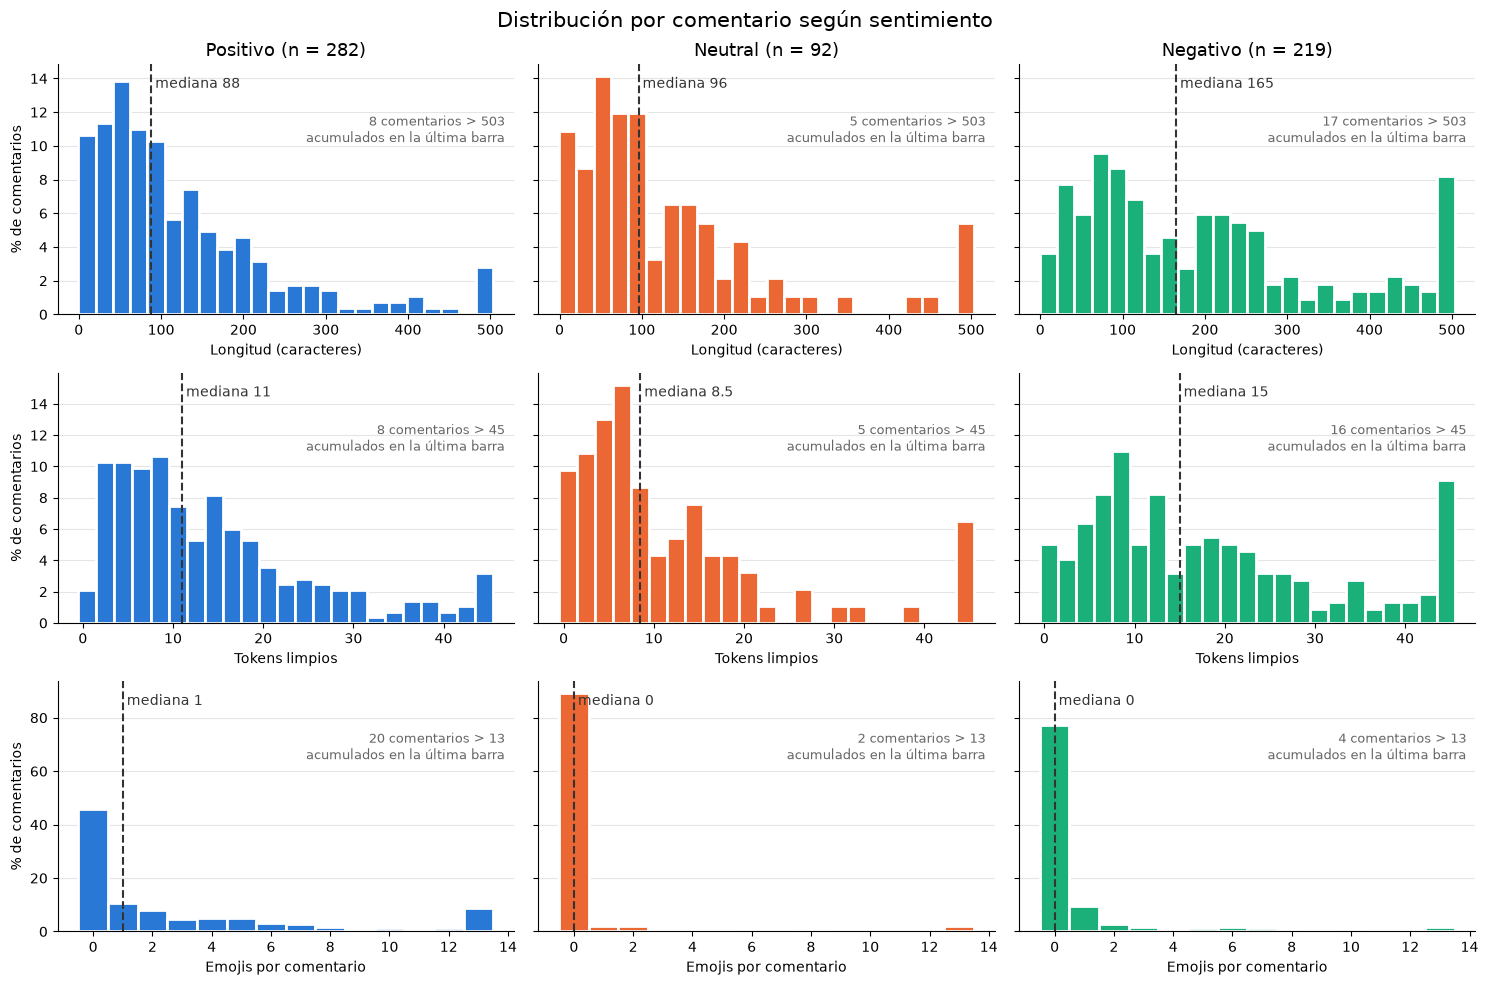

In [5]:
import matplotlib.pyplot as plt

CATEGORIAS = ["positivo", "neutral", "negativo"]
COLOR_SENT = {"positivo": "#2a78d6", "neutral": "#eb6834", "negativo": "#1baf7a"}
METRICAS = {
    "caracteres": "Longitud (caracteres)",
    "tokens_limpios": "Tokens limpios",
    "emojis": "Emojis por comentario",
}

fig, ejes = plt.subplots(len(METRICAS), len(CATEGORIAS), figsize=(15, 10), sharey="row")
for fila, (col, etiqueta) in enumerate(METRICAS.items()):
    tope = int(np.ceil(stats[col].quantile(0.95)))  # recorta la cola larga para que se vea el cuerpo de la distribución
    paso = max(1, int(np.ceil((tope + 1) / 25)))
    bordes = np.arange(0, tope + paso + 1, paso) - 0.5  # barras alineadas a valores enteros
    for c, cat in enumerate(CATEGORIAS):
        eje = ejes[fila, c]
        valores = stats.loc[stats["sentimiento"] == cat, col]
        fuera = (valores > tope).sum()
        eje.hist(valores.clip(upper=tope), bins=bordes, weights=np.full(len(valores), 100 / len(valores)),
                 color=COLOR_SENT[cat], edgecolor="white", linewidth=2)
        mediana = valores.median()
        eje.axvline(mediana, color="#333333", linewidth=1.5, linestyle="--")
        eje.text(mediana, 0.95, f" mediana {mediana:g}", transform=eje.get_xaxis_transform(), va="top", fontsize=10, color="#333333")
        if fuera:
            eje.text(0.98, 0.80, f"{fuera} comentarios > {tope}\nacumulados en la última barra", transform=eje.transAxes,
                     ha="right", va="top", fontsize=9, color="#666666")
        if fila == 0:
            eje.set_title(f"{cat.capitalize()} (n = {len(valores)})", fontsize=13)
        if c == 0:
            eje.set_ylabel("% de comentarios")
        eje.set_xlabel(etiqueta)
        eje.grid(axis="y", color="#e5e5e5", linewidth=0.8)
        eje.set_axisbelow(True)
        eje.spines[["top", "right"]].set_visible(False)
fig.suptitle("Distribución por comentario según sentimiento", fontsize=15)
plt.tight_layout()
plt.show()

Nube de palabras del texto limpio por categoría de sentimiento. `WordCloud` no sabe dibujar emojis a color, así que cada emoji ocupa en el acomodo un marcador sólido del mismo tamaño y al dibujar se pega encima la imagen del emoji con la fuente Apple Color Emoji.

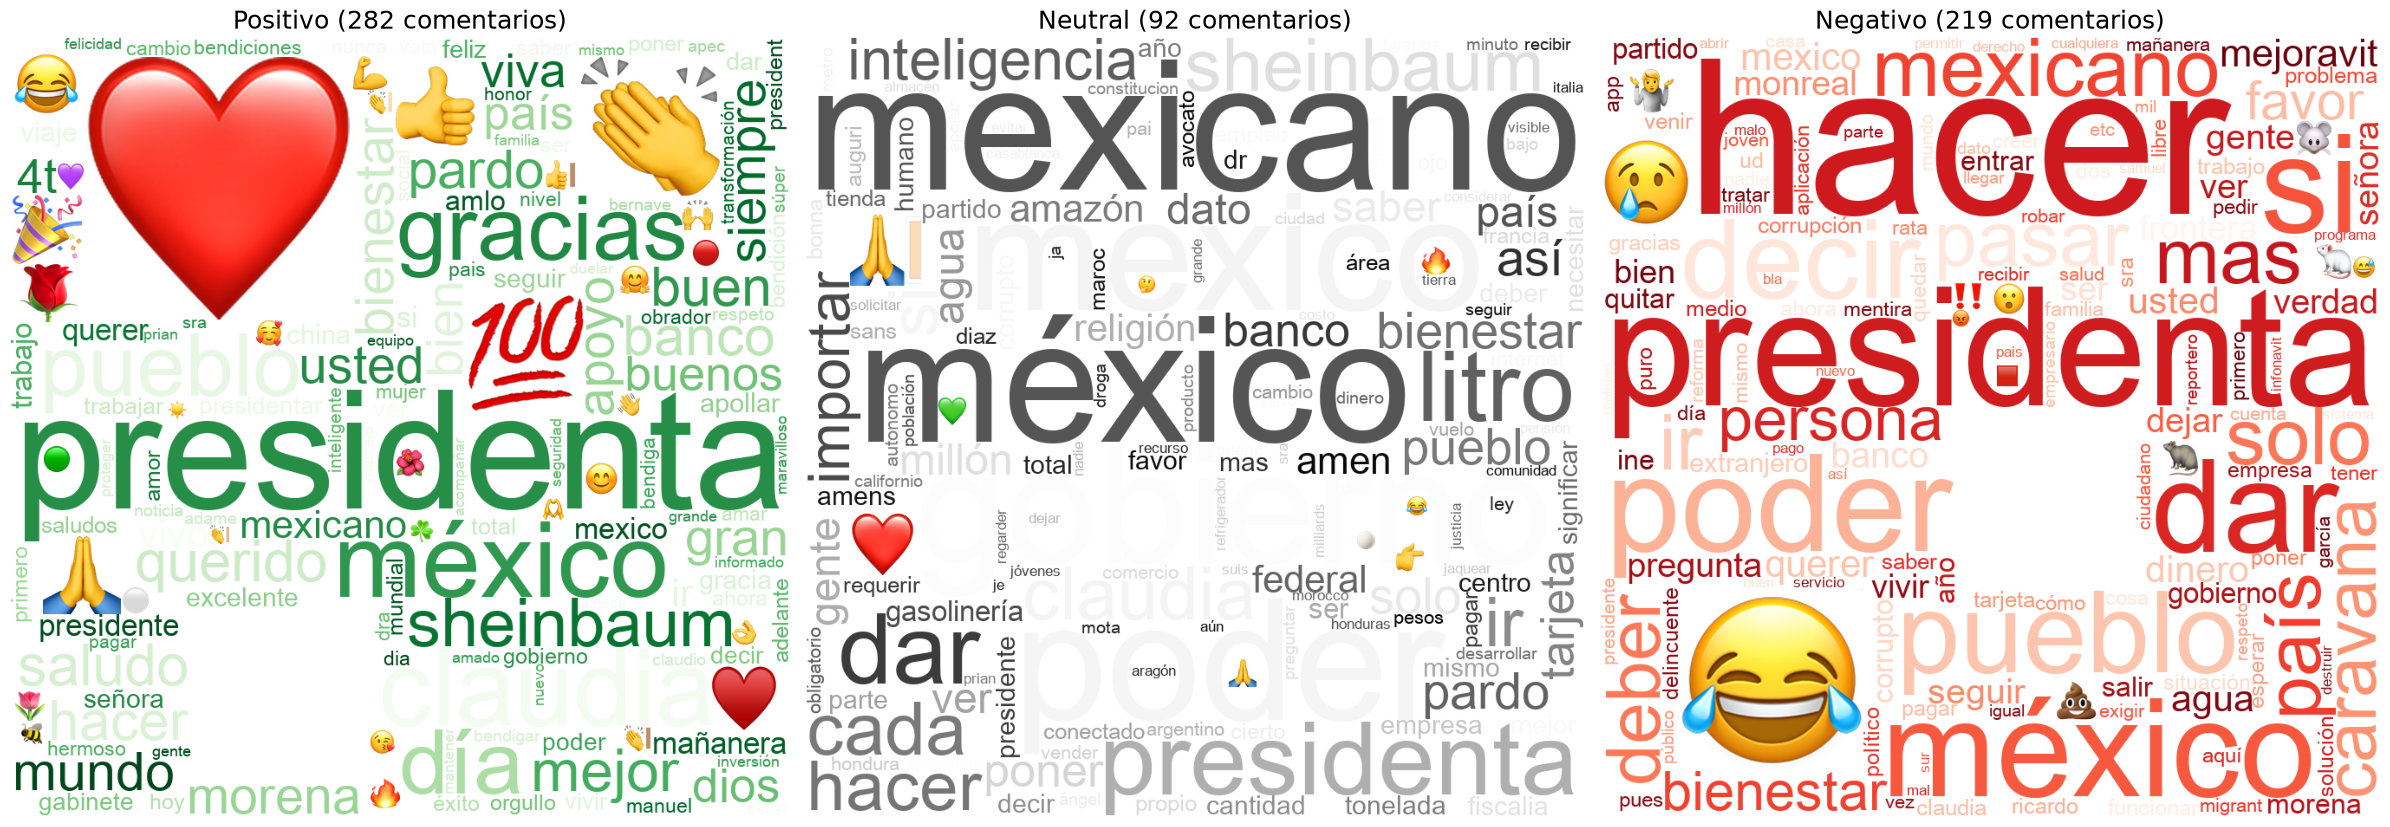

In [6]:
from collections import Counter

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from wordcloud import WordCloud

FUENTE_TEXTO = "/System/Library/Fonts/Supplemental/Arial Unicode.ttf"
FUENTE_EMOJI = ImageFont.truetype("/System/Library/Fonts/Apple Color Emoji.ttc", 160)
COLORES = {"positivo": "Greens", "neutral": "Greys", "negativo": "Reds"}


def imagen_emoji(e):
    lienzo = Image.new("RGBA", (220, 220))
    ImageDraw.Draw(lienzo).text((10, 10), e, font=FUENTE_EMOJI, embedded_color=True)
    return lienzo.crop(lienzo.getbbox())


# Marcadores sólidos para reservar el lugar de cada emoji: dos bloques "██" (casi un cuadrado) más una
# marca combinante distinta que queda dentro del bloque, así cada marcador es único y tiene la misma caja.
_fuente = ImageFont.truetype(FUENTE_TEXTO, 100)
_caja = _fuente.getbbox("██", anchor="lt")
MARCADORES = ["██"] + ["██" + chr(c) for c in range(0x300, 0x370) if _fuente.getbbox("██" + chr(c), anchor="lt") == _caja]


class NubeConEmojis(WordCloud):
    """WordCloud que acomoda cada emoji con un marcador sólido y al dibujar pega el emoji a color."""

    def generar(self, frecuencias):
        emojis = [t for t, _ in Counter(frecuencias).most_common() if es_emoji(t)][: len(MARCADORES)]
        self.marcadores = dict(zip(MARCADORES, emojis))
        inverso = {e: m for m, e in self.marcadores.items()}
        frec = {inverso.get(t, t): n for t, n in frecuencias.items() if t in inverso or not es_emoji(t)}
        return self.generate_from_frequencies(frec)

    def to_image(self):
        self._check_generated()
        img = Image.new("RGB", (int(self.width * self.scale), int(self.height * self.scale)), self.background_color)
        draw = ImageDraw.Draw(img)
        for (palabra, _), tam, posicion, orientacion, color in self.layout_:
            fuente = ImageFont.TransposedFont(ImageFont.truetype(self.font_path, int(tam * self.scale)), orientation=orientacion)
            xy = (int(posicion[1] * self.scale), int(posicion[0] * self.scale))
            if palabra in self.marcadores:
                x0, y0, x1, y1 = draw.textbbox(xy, palabra, font=fuente)
                lado = min(x1 - x0, y1 - y0)
                icono = imagen_emoji(self.marcadores[palabra]).resize((lado, lado), Image.LANCZOS)
                img.paste(icono, ((x0 + x1 - lado) // 2, (y0 + y1 - lado) // 2), icono)
            else:
                draw.text(xy, palabra, fill=color, font=fuente)
        return img


fig, ejes = plt.subplots(1, 3, figsize=(24, 9))
for eje, (categoria, cmap) in zip(ejes, COLORES.items()):
    frecuencias = Counter(" ".join(aux.loc[aux["sentimiento"] == categoria, "texto_limpio"]).split())
    nube = NubeConEmojis(width=900, height=900, background_color="white", font_path=FUENTE_TEXTO,
                         colormap=cmap, max_words=150, max_font_size=250, random_state=42).generar(frecuencias)
    eje.imshow(nube.to_image())
    eje.set_title(f"{categoria.capitalize()} ({(aux['sentimiento'] == categoria).sum()} comentarios)", fontsize=18)
    eje.axis("off")
plt.tight_layout()
plt.show()

Vector de características por comentario:

| Variable | Definición |
|---|---|
| `x1_emojis` | número de emojis en el texto |
| `x2_corazon` | 1 si tiene algún emoji de corazón (❤ 💜 💚 💕 🫶 🥰 😍 😘, etc.) o `<3` |
| `x3_groserias` | número de groserías, con un léxico de vulgaridades del español de México; detecta variantes con letras repetidas, sin acentos y en *leetspeak* (`P3NDEJ0`) |
| `x4_longitud` | longitud del comentario en caracteres |
| `x5_faltas` | número de palabras que no reconoce el diccionario Hunspell `es_MX` de LibreOffice (vía `spylls`); se omiten las palabras con mayúscula inicial (nombres propios), las de menos de 3 letras y un vocabulario político del contexto (AMLO, 4T, PRIAN, mañanera...) |
| `x6_morena` | 1 si menciona a Morena (morena, morenista, moreninis) |
| `x7_pan` | 1 si menciona al PAN (PAN, panista) |
| `x8_pri` | 1 si menciona al PRI (PRI, priista) |
| `x9_prian` | 1 si menciona al "PRIAN" (incluye MCPRIAN, prianistas) |

In [7]:
import unicodedata
import urllib.request
from functools import lru_cache

from spylls.hunspell import Dictionary

# Diccionario Hunspell es_MX de LibreOffice; se descarga una sola vez a data/diccionarios (gitignored)
DICC = RAIZ / "data" / "diccionarios"
DICC.mkdir(parents=True, exist_ok=True)
for ext in ("dic", "aff"):
    if not (DICC / f"es_MX.{ext}").exists():
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/LibreOffice/dictionaries/master/es/es_MX.{ext}", DICC / f"es_MX.{ext}")
HUNSPELL = Dictionary.from_files(str(DICC / "es_MX"))

CORAZONES = {normalizar_emoji(e) for e in "❤️ ♥️ 💜 💚 💙 🧡 💛 🖤 🤍 🤎 💕 💖 💗 💓 💞 💘 💝 💟 ❣️ 🫶 🥰 😍 😘 ❤️‍🔥 ❤️‍🩹 💌".split()}
GROSERIAS = re.compile(
    r"\b(pinche\w*|pendej\w*|ching\w*|put[oa]s?|mierd\w*|cabron\w*|verga\w*|culer\w*|mamad\w*|mamar|mamon\w*"
    r"|carajo|jod\w*|idiota\w*|estupid\w*|imbecil\w*|pocamadre|ojete\w*|huevon\w*|tarad\w*|osicon\w*|babos\w*"
    r"|nacos?|zorr[ao]s?|perras?|brut[oa]s?|madrazo\w*|cagad\w*|culo)\b"
)
VOCAB_CONTEXTO = {
    "amlo", "sheinbaum", "morena", "morenista", "morenistas", "prian", "prianistas", "mcprian", "panista", "panistas",
    "priista", "priistas", "mañanera", "mañaneras", "chayotero", "chayoteros", "pluris", "plurinominales", "infonavit",
    "mejoravit", "imss", "issste", "cfe", "apec", "ine", "taddei", "ebrard", "monreal", "noroña", "harfuch", "bienestar",
}
LEET = str.maketrans({"0": "o", "4": "a", "3": "e", "$": "s", "1": "i"})
LETRAS = re.compile(r"[^\W\d_]+")


def normalizar(s):
    """Minúsculas, sin acentos, sin leetspeak y sin letras repetidas más de dos veces."""
    s = "".join(c for c in unicodedata.normalize("NFD", s.lower()) if unicodedata.category(c) != "Mn")
    return re.sub(r"(\w)\1{2,}", r"\1", s.translate(LEET))


@lru_cache(maxsize=None)
def bien_escrita(palabra):
    minus = palabra.lower()
    return minus in VOCAB_CONTEXTO or HUNSPELL.lookup(palabra) or HUNSPELL.lookup(minus)


def contar_faltas(texto):
    palabras = [w for w in LETRAS.findall(texto) if len(w) >= 3 and not (w[0].isupper() and w[1:].islower())]
    return sum(not bien_escrita(w) for w in palabras)


def vector(texto):
    emojis = [normalizar_emoji(e["emoji"]) for e in emoji.emoji_list(texto)]
    n = normalizar(texto)
    return {
        "x1_emojis": len(emojis),
        "x2_corazon": int(any(e in CORAZONES for e in emojis) or "<3" in texto),
        "x3_groserias": len(GROSERIAS.findall(n)),
        "x4_longitud": len(texto),
        "x5_faltas": contar_faltas(texto),
        "x6_morena": int(bool(re.search(r"\bmoren(a|ista|istas|inis)\b", n))),
        "x7_pan": int(bool(re.search(r"\bpan(ista|istas|ismo)?\b", n))),
        "x8_pri": int(bool(re.search(r"\bpri(i?stas?|ismo|hista?s?)?\b", n))),
        "x9_prian": int("prian" in n),
    }


X = pd.DataFrame([vector(s) for s in aux["text"].fillna("")])
y = aux["sentimiento"]
display(X.describe().round(2))
display(X.assign(sentimiento=y).groupby("sentimiento").mean().round(2).loc[CATEGORIAS])

,x1_emojis,x2_corazon,x3_groserias,x4_longitud,x5_faltas,x6_morena,x7_pan,x8_pri,x9_prian
count,593.00,593.00,593.00,593.00,593.00,593.00,593.00,593.00,593.00
mean,2.27,0.14,0.05,179.28,1.58,0.04,0.01,0.01,0.03
std,5.42,0.35,0.40,277.91,4.07,0.20,0.12,0.09,0.18
min,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,53.00,0.00,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,106.00,0.00,0.00,0.00,0.00,0.00
75%,2.00,0.00,0.00,211.00,2.00,0.00,0.00,0.00,0.00
max,44.00,1.00,8.00,3413.00,65.00,1.00,1.00,1.00,1.00


,x1_emojis,x2_corazon,x3_groserias,x4_longitud,x5_faltas,x6_morena,x7_pan,x8_pri,x9_prian
sentimiento,,,,,,,,,
positivo,3.55,0.28,0.01,127.72,0.90,0.05,0.00,0.00,0.04
neutral,0.60,0.03,0.00,193.78,1.88,0.01,0.00,0.01,0.03
negativo,1.34,0.00,0.12,239.60,2.32,0.05,0.03,0.01,0.03


Partición estratificada 75 / 25. El conjunto de prueba se reserva para la evaluación final: la selección del modelo se hace solo con validación cruzada de 5 particiones sobre el entrenamiento, para no filtrar información de la prueba. Como la clase neutral es minoritaria (16 %), las métricas principales son la exactitud balanceada y el F1 macro.

In [8]:
import os

# en macOS, LightGBM y XGBoost cargan cada uno su libomp; esto evita el choque y limita hilos
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import warnings

from lazypredict.Supervised import LazyClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split

warnings.filterwarnings("ignore")
SEMILLA = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
print(f"entrenamiento: {len(X_train)}  prueba: {len(X_test)}")

lazy = LazyClassifier(verbose=0, ignore_warnings=True, cv=5, n_jobs=1, random_state=SEMILLA)
ranking, _ = lazy.fit(X_train, X_test, y_train, y_test)
ranking = ranking.sort_values("Balanced Accuracy CV Mean", ascending=False)
ranking.head(15).round(3)

entrenamiento: 444  prueba: 149


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Accuracy CV Mean,Accuracy CV Std,Balanced Accuracy CV Mean,Balanced Accuracy CV Std,ROC AUC CV Mean,ROC AUC CV Std,F1 Score CV Mean,F1 Score CV Std,Precision CV Mean,Precision CV Std,Recall CV Mean,Recall CV Std,Time Taken
Model,,,,,,,,,,,,,,,,,,,
Perceptron,0.591,0.442,NaN,0.518,0.521,0.591,0.513,0.059,0.472,0.066,NaN,NaN,0.504,0.058,0.590,0.080,0.513,0.059,0.038
PassiveAggressiveClassifier,0.597,0.445,NaN,0.522,0.531,0.597,0.484,0.051,0.465,0.062,NaN,NaN,0.465,0.030,0.584,0.088,0.484,0.051,0.039
BernoulliNB,0.631,0.486,0.763,0.574,0.534,0.631,0.579,0.035,0.449,0.026,0.714,0.058,0.529,0.031,0.496,0.032,0.579,0.035,0.046
LinearDiscriminantAnalysis,0.617,0.484,0.761,0.569,0.529,0.617,0.563,0.045,0.445,0.036,0.692,0.038,0.516,0.041,0.485,0.043,0.563,0.045,0.045
LGBMClassifier,0.570,0.530,0.701,0.575,0.581,0.570,0.518,0.062,0.444,0.062,0.645,0.065,0.509,0.064,0.505,0.065,0.518,0.062,2.382
LinearSVC,0.624,0.478,NaN,0.564,0.532,0.624,0.574,0.040,0.443,0.033,NaN,NaN,0.521,0.038,0.492,0.040,0.574,0.040,0.038
NearestCentroid,0.416,0.481,0.784,0.459,0.679,0.416,0.374,0.018,0.443,0.033,0.701,0.033,0.391,0.034,0.592,0.048,0.374,0.018,0.046
RidgeClassifierCV,0.631,0.486,NaN,0.574,0.532,0.631,0.570,0.034,0.442,0.028,NaN,NaN,0.520,0.032,0.489,0.034,0.570,0.034,0.037
RidgeClassifier,0.617,0.477,NaN,0.563,0.519,0.617,0.567,0.040,0.442,0.032,NaN,NaN,0.519,0.036,0.485,0.036,0.567,0.040,0.037


TPOT con un cliente de Dask en modo hilos (`processes=False`): en macOS los procesos hijos de Dask suelen colgarse dentro de Jupyter, así que todo corre en el mismo proceso, con tiempo máximo acotado.

In [9]:
from dask.distributed import Client, LocalCluster
from tpot import TPOTClassifier

with LocalCluster(n_workers=1, threads_per_worker=2, processes=False, dashboard_address=None) as cluster, Client(cluster) as cliente:
    tpot = TPOTClassifier(
        search_space="linear-light", scorers=["balanced_accuracy"], scorers_weights=[1], cv=CV,
        generations=10, population_size=30, max_time_mins=5, max_eval_time_mins=0.5,
        client=cliente, random_state=SEMILLA, verbose=0,
    )
    tpot.fit(X_train, y_train)

tpot.fitted_pipeline_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('variancethreshold', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['x1_emojis','x2_corazon','x3_groserias',...,'x7_pan','x8_pri','x9_prian']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Selección del modelo final: se comparan con la misma validación cruzada los tres mejores de LazyPredict y el pipeline de TPOT, junto con dos líneas base que no aprenden nada (clase más frecuente y aleatorio estratificado).

In [10]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

modelos_lazy = lazy.provide_models(X_train, X_test, y_train, y_test)
# los tres mejores de LazyPredict que entregan probabilidades (necesarias para ROC y SHAP)
con_proba = [n for n in ranking.index if n in modelos_lazy and hasattr(modelos_lazy[n], "predict_proba")]
candidatos = {nombre: modelos_lazy[nombre] for nombre in con_proba[:3]}
candidatos["TPOT"] = tpot.fitted_pipeline_
candidatos["Línea base: clase más frecuente"] = DummyClassifier(strategy="most_frequent")
candidatos["Línea base: aleatorio estratificado"] = DummyClassifier(strategy="stratified", random_state=SEMILLA)

METRICAS_CV = {"exactitud": "accuracy", "exactitud_balanceada": "balanced_accuracy", "f1_macro": "f1_macro", "roc_auc_ovr": "roc_auc_ovr"}
filas = {}
for nombre, modelo in candidatos.items():
    r = cross_validate(clone(modelo), X_train, y_train, cv=CV, scoring=METRICAS_CV, return_train_score=True)
    filas[nombre] = {
        "exactitud_balanceada (train)": r["train_exactitud_balanceada"].mean(),
        "exactitud_balanceada (CV)": r["test_exactitud_balanceada"].mean(),
        "± sd CV": r["test_exactitud_balanceada"].std(),
        "f1_macro (CV)": r["test_f1_macro"].mean(),
        "roc_auc_ovr (CV)": r["test_roc_auc_ovr"].mean(),
        "brecha train − CV": r["train_exactitud_balanceada"].mean() - r["test_exactitud_balanceada"].mean(),
    }
comparacion = pd.DataFrame(filas).T.sort_values("exactitud_balanceada (CV)", ascending=False)

reales = [n for n in comparacion.index if not n.startswith("Línea base")]
NOMBRE_FINAL = reales[0]
modelo_final = clone(candidatos[NOMBRE_FINAL]).fit(X_train, y_train)
print("Modelo final:", NOMBRE_FINAL)
comparacion.round(3)

Modelo final: TPOT


,exactitud_balanceada (train),exactitud_balanceada (CV),± sd CV,f1_macro (CV),roc_auc_ovr (CV),brecha train − CV
TPOT,0.585,0.576,0.033,0.534,0.713,0.008
BernoulliNB,0.459,0.466,0.020,0.428,0.706,-0.007
LinearDiscriminantAnalysis,0.468,0.450,0.021,0.408,0.660,0.018
LGBMClassifier,0.722,0.408,0.022,0.402,0.624,0.314
Línea base: aleatorio estratificado,0.331,0.339,0.015,0.341,0.502,-0.009
Línea base: clase más frecuente,0.333,0.333,0.000,0.215,0.500,0.000


Evaluación en el conjunto de prueba (una sola vez) y control de sobreajuste: se comparan las métricas en entrenamiento, validación cruzada y prueba, y la curva de aprendizaje muestra si la brecha entre entrenamiento y validación se cierra al crecer la muestra.

,entrenamiento,validación cruzada,prueba,línea base (prueba)
exactitud,0.556,0.550,0.577,0.477
exactitud_balanceada,0.586,0.576,0.585,0.333
f1_macro,0.541,0.534,0.554,0.215
roc_auc_ovr,0.732,0.713,0.779,0.500


              precision    recall  f1-score   support

    positivo      0.851     0.563     0.678        71
     neutral      0.269     0.609     0.373        23
    negativo      0.640     0.582     0.610        55

    accuracy                          0.577       149
   macro avg      0.587     0.585     0.554       149
weighted avg      0.683     0.577     0.606       149



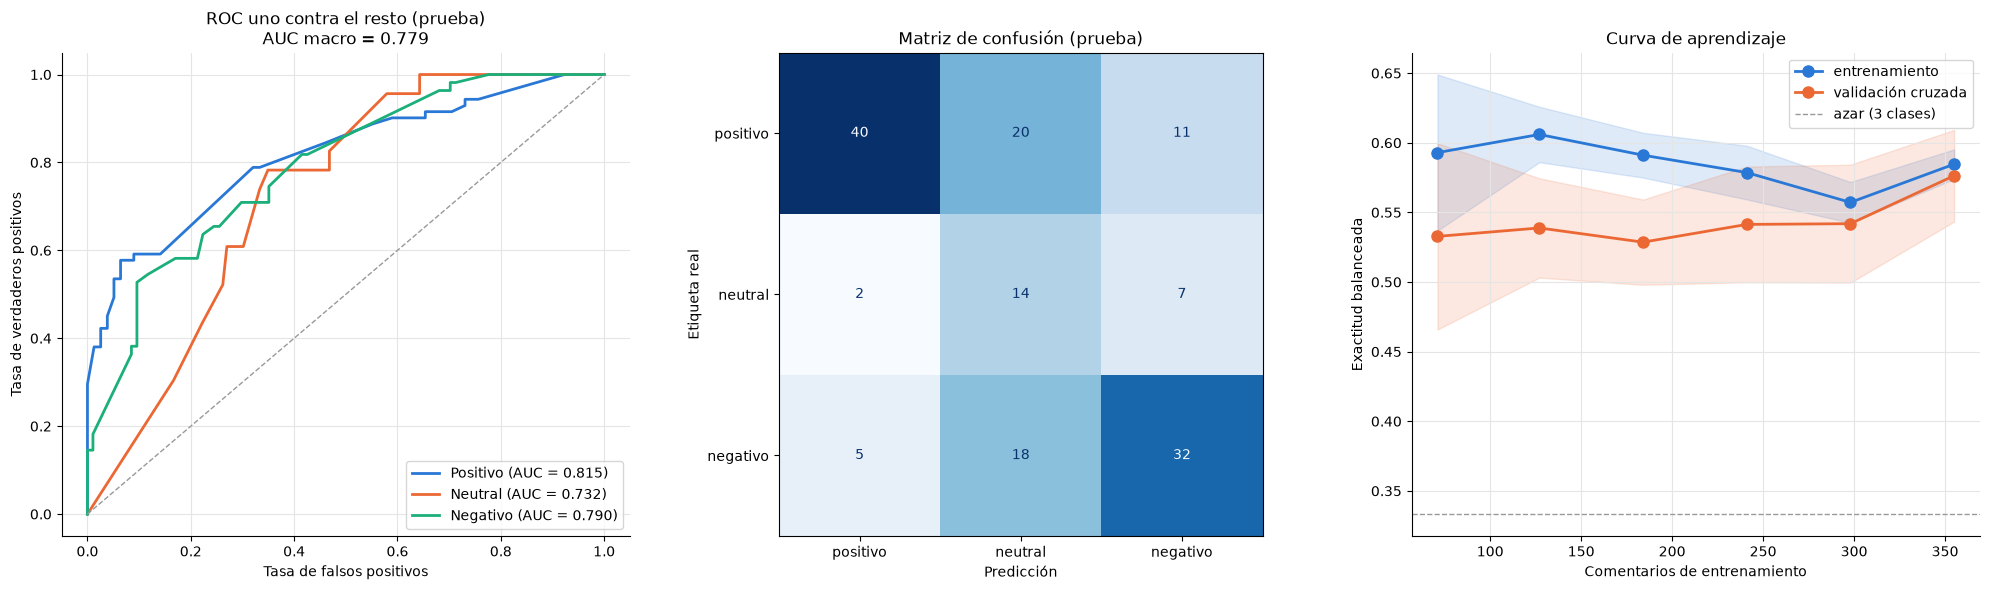

In [11]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, auc, balanced_accuracy_score,
    classification_report, f1_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import learning_curve


def metricas(modelo, X_, y_):
    proba = modelo.predict_proba(X_)
    pred = modelo.classes_[proba.argmax(axis=1)]
    return {
        "exactitud": accuracy_score(y_, pred),
        "exactitud_balanceada": balanced_accuracy_score(y_, pred),
        "f1_macro": f1_score(y_, pred, average="macro"),
        "roc_auc_ovr": roc_auc_score(y_, proba, multi_class="ovr", labels=modelo.classes_),
    }


cv_final = cross_validate(clone(candidatos[NOMBRE_FINAL]), X_train, y_train, cv=CV, scoring=METRICAS_CV)
tabla = pd.DataFrame({
    "entrenamiento": metricas(modelo_final, X_train, y_train),
    "validación cruzada": {k: cv_final[f"test_{k}"].mean() for k in METRICAS_CV},
    "prueba": metricas(modelo_final, X_test, y_test),
    "línea base (prueba)": metricas(DummyClassifier(strategy="most_frequent").fit(X_train, y_train), X_test, y_test),
})
display(tabla.round(3))
print(classification_report(y_test, modelo_final.predict(X_test), labels=CATEGORIAS, digits=3))

fig, ejes = plt.subplots(1, 3, figsize=(20, 6))

# ROC uno contra el resto, una curva por clase
proba_test = modelo_final.predict_proba(X_test)
for cat in CATEGORIAS:
    k = list(modelo_final.classes_).index(cat)
    fpr, tpr, _ = roc_curve(y_test == cat, proba_test[:, k])
    ejes[0].plot(fpr, tpr, color=COLOR_SENT[cat], linewidth=2, label=f"{cat.capitalize()} (AUC = {auc(fpr, tpr):.3f})")
ejes[0].plot([0, 1], [0, 1], color="#999999", linestyle="--", linewidth=1)
ejes[0].set_xlabel("Tasa de falsos positivos")
ejes[0].set_ylabel("Tasa de verdaderos positivos")
ejes[0].legend(loc="lower right")
ejes[0].set_title(f"ROC uno contra el resto (prueba)\nAUC macro = {tabla.loc['roc_auc_ovr', 'prueba']:.3f}")

# matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, modelo_final.predict(X_test), labels=CATEGORIAS, cmap="Blues",
                                        colorbar=False, ax=ejes[1])
ejes[1].set_title("Matriz de confusión (prueba)")
ejes[1].set_xlabel("Predicción")
ejes[1].set_ylabel("Etiqueta real")

# curva de aprendizaje
tam, sc_train, sc_val = learning_curve(clone(candidatos[NOMBRE_FINAL]), X_train, y_train, cv=CV,
                                       scoring="balanced_accuracy", train_sizes=np.linspace(0.2, 1.0, 6))
for sc, etiqueta, color in [(sc_train, "entrenamiento", "#2a78d6"), (sc_val, "validación cruzada", "#eb6834")]:
    ejes[2].plot(tam, sc.mean(axis=1), marker="o", markersize=8, linewidth=2, color=color, label=etiqueta)
    ejes[2].fill_between(tam, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=color, alpha=0.15)
ejes[2].axhline(1 / 3, color="#999999", linestyle="--", linewidth=1, label="azar (3 clases)")
ejes[2].set_xlabel("Comentarios de entrenamiento")
ejes[2].set_ylabel("Exactitud balanceada")
ejes[2].set_title("Curva de aprendizaje")
ejes[2].legend()
for eje in ejes[[0, 2]]:
    eje.grid(color="#e5e5e5", linewidth=0.8)
    eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Explicabilidad (XAI). SHAP con `PermutationExplainer` sobre las probabilidades del modelo final funciona con cualquier tipo de modelo; la importancia por permutación en el conjunto de prueba sirve como contraste independiente.

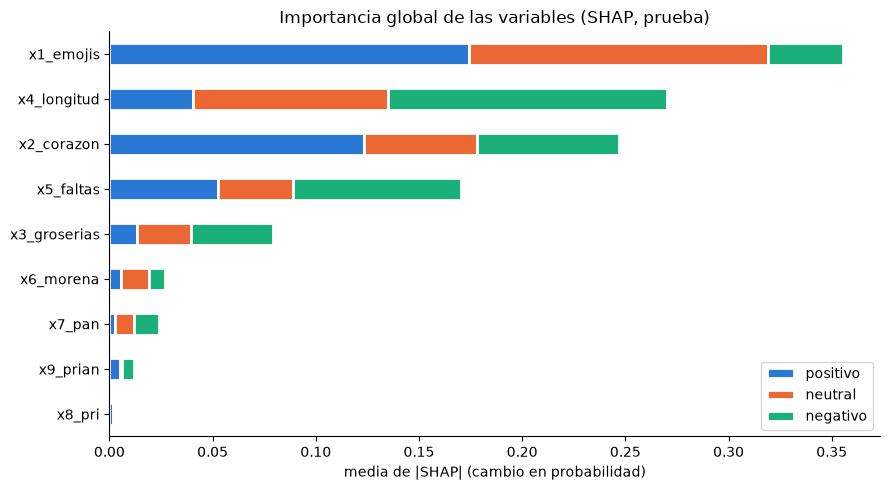

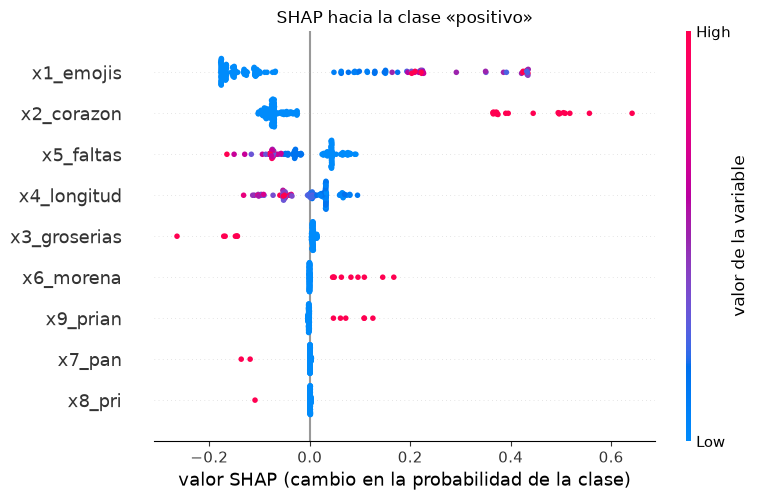

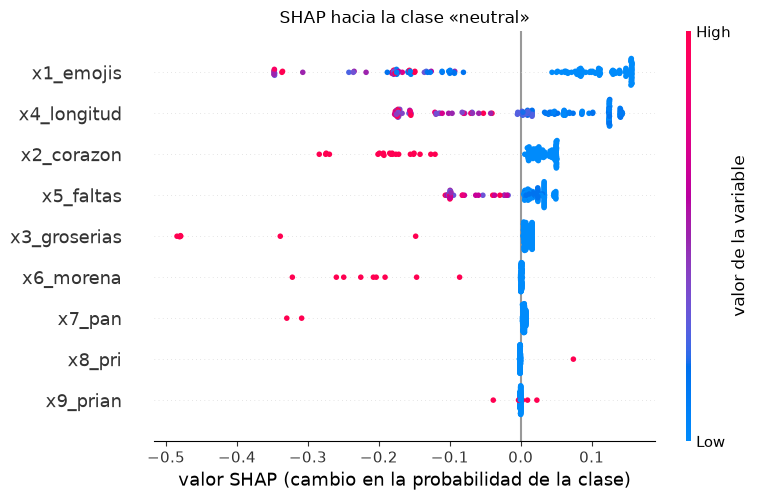

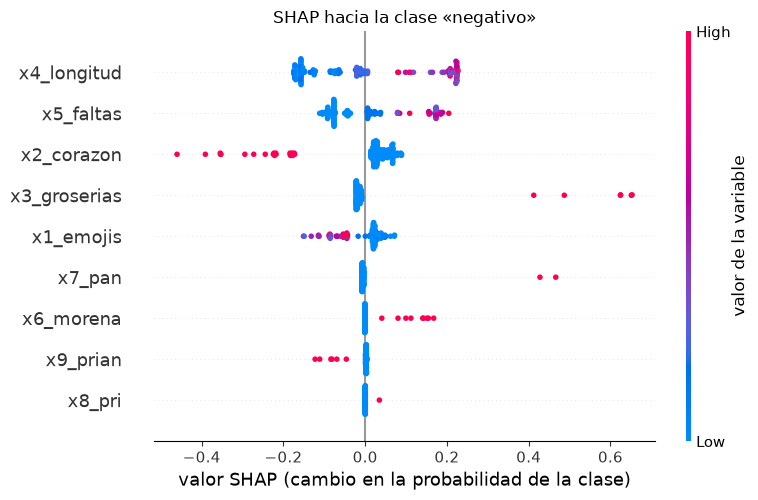

,caída media en exactitud balanceada,sd
x1_emojis,0.090,0.029
x4_longitud,0.052,0.036
x2_corazon,0.045,0.020
x3_groserias,0.030,0.012
x6_morena,0.012,0.013
x5_faltas,0.005,0.016
x7_pan,0.002,0.008
x8_pri,-0.000,0.004
x9_prian,-0.001,0.007


In [12]:
import shap
from sklearn.inspection import permutation_importance

fondo = shap.sample(X_train, 100, random_state=SEMILLA)
explicador = shap.Explainer(modelo_final.predict_proba, fondo, algorithm="permutation", seed=SEMILLA)
valores = explicador(X_test)
clases = list(modelo_final.classes_)

# importancia global: media de |SHAP| por variable y clase
importancia = pd.DataFrame({c: np.abs(valores.values[:, :, clases.index(c)]).mean(axis=0) for c in CATEGORIAS}, index=X.columns)
importancia = importancia.loc[importancia.sum(axis=1).sort_values().index]
fig, eje = plt.subplots(figsize=(9, 5))
importancia.plot.barh(stacked=True, color=[COLOR_SENT[c] for c in CATEGORIAS], edgecolor="white", linewidth=2, ax=eje)
eje.set_xlabel("media de |SHAP| (cambio en probabilidad)")
eje.set_title("Importancia global de las variables (SHAP, prueba)")
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# dirección del efecto en cada clase
for c in CATEGORIAS:
    shap.plots.beeswarm(valores[:, :, clases.index(c)], max_display=9, show=False)
    plt.title(f"SHAP hacia la clase «{c}»")
    plt.xlabel("valor SHAP (cambio en la probabilidad de la clase)")
    plt.gcf().axes[-1].set_ylabel("valor de la variable")
    plt.tight_layout()
    plt.show()

perm = permutation_importance(modelo_final, X_test, y_test, scoring="balanced_accuracy", n_repeats=30, random_state=SEMILLA)
pd.DataFrame({"caída media en exactitud balanceada": perm.importances_mean, "sd": perm.importances_std},
             index=X.columns).sort_values("caída media en exactitud balanceada", ascending=False).round(3)

Lectura de los resultados (cifras de esta ejecución; TPOT tiene un límite de tiempo, así que una nueva corrida puede elegir un pipeline algo distinto):

- El mejor modelo por validación cruzada es el pipeline de TPOT: escalado, transformación por cuantiles y un Bernoulli Naive Bayes sin probabilidades a priori (`fit_prior=False`), lo que equilibra las clases. Supera a los tres mejores de LazyPredict y a las líneas base.
- No hay sobreajuste: la exactitud balanceada es 0.586 en entrenamiento, 0.576 en validación cruzada y 0.585 en prueba, y la curva de aprendizaje muestra que las dos curvas convergen. El caso opuesto es LightGBM, con 0.72 en entrenamiento y 0.41 en validación cruzada; por eso no se eligió.
- En prueba, el modelo alcanza una exactitud balanceada de 0.585 y un AUC macro de 0.779, frente a 0.333 y 0.500 de la línea base. La clase positiva es la mejor separada (AUC 0.815); la neutral es la más difícil (precisión 0.27), porque el modelo le asigna muchos comentarios negativos y positivos sin emojis.
- Con estas nueve variables el techo es modesto: describen la forma del comentario (emojis, longitud, ortografía, groserías) y casi nada de su contenido. Para mejorar habría que sumar el texto, por ejemplo TF-IDF o embeddings sobre `texto_limpio`.
- XAI: las variables más influyentes son el número de emojis, la longitud y el corazón. Los emojis y el corazón empujan hacia «positivo»; la longitud, las faltas de ortografía y las groserías empujan hacia «negativo». Las menciones a partidos casi no aportan porque aparecen en menos del 5 % de los comentarios; mencionar a Morena o al PRIAN inclina levemente hacia «positivo» y mencionar al PAN o al PRI, hacia «negativo». La importancia por permutación confirma el mismo orden.

Segundo entrenamiento con embeddings. El procedimiento es idéntico al anterior (misma partición, misma validación cruzada, LazyPredict, TPOT, evaluación y XAI); solo cambia el vector de entrada:

1. Cada comentario original (con emojis) se convierte en un embedding de 768 dimensiones con `embeddinggemma` servido por Ollama en un servidor con GPU, con el prefijo de tarea `task: classification | query:` que recomienda el modelo.
2. PCA reduce los embeddings a 5 componentes. El PCA se ajusta solo con los comentarios de entrenamiento y después se aplica a los de prueba, para no filtrar información.

Los embeddings se guardan en `data/youtube_comments/` y en ejecuciones posteriores se leen de ahí, así que el servidor de Ollama solo hace falta la primera vez.

In [13]:
import json
import urllib.request

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")  # servidor de Ollama con GPU
MODELO_EMB = "embeddinggemma"
CACHE_EMB = DATOS / "_OoWAqo4FSk_embeddings_gemma.npz"


def embeber(textos, lote=32):
    vectores = []
    for i in range(0, len(textos), lote):
        cuerpo = {"model": MODELO_EMB, "input": [f"task: classification | query: {t}" for t in textos[i:i + lote]]}
        peticion = urllib.request.Request(f"{OLLAMA}/api/embed", data=json.dumps(cuerpo).encode(),
                                          headers={"Content-Type": "application/json"})
        with urllib.request.urlopen(peticion, timeout=300) as r:
            vectores += json.loads(r.read())["embeddings"]
    return np.array(vectores, dtype=np.float32)


cache = np.load(CACHE_EMB) if CACHE_EMB.exists() else None
if cache is not None and cache["ids"].tolist() == aux["id"].tolist():
    emb = cache["emb"]
else:
    emb = embeber(aux["text"].fillna("").tolist())
    np.savez_compressed(CACHE_EMB, ids=aux["id"].to_numpy(dtype=str), emb=emb)

E = pd.DataFrame(emb, index=aux.index)
print("embeddings:", E.shape)

embeddings: (593, 768)


varianza explicada por componente: [0.113 0.07  0.045 0.033 0.032] (total 29.4%)


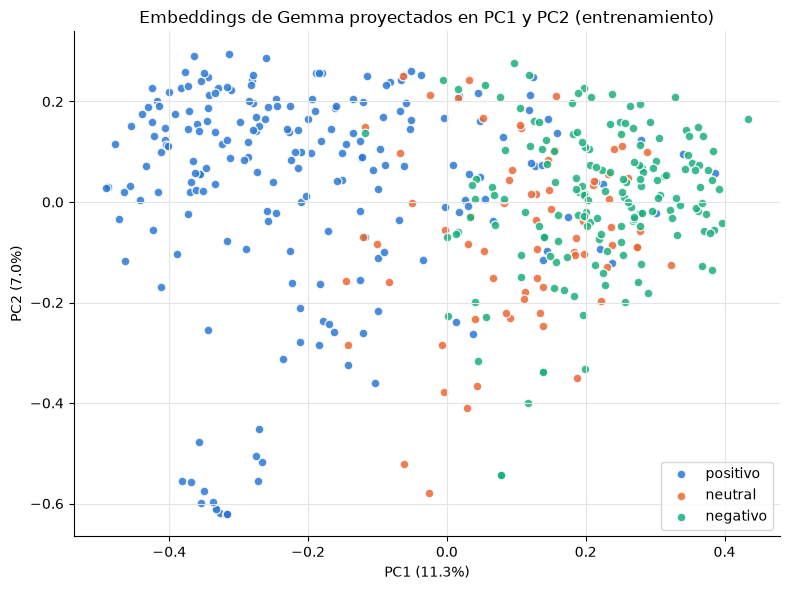

In [14]:
from sklearn.decomposition import PCA

COMPONENTES = [f"pc{i}" for i in range(1, 6)]
pca = PCA(n_components=5, random_state=SEMILLA).fit(E.loc[X_train.index])
Xe_train = pd.DataFrame(pca.transform(E.loc[X_train.index]), index=X_train.index, columns=COMPONENTES)
Xe_test = pd.DataFrame(pca.transform(E.loc[X_test.index]), index=X_test.index, columns=COMPONENTES)

print("varianza explicada por componente:", pca.explained_variance_ratio_.round(3),
      f"(total {pca.explained_variance_ratio_.sum():.1%})")

fig, eje = plt.subplots(figsize=(8, 6))
for cat in CATEGORIAS:
    m = y_train == cat
    eje.scatter(Xe_train.loc[m, "pc1"], Xe_train.loc[m, "pc2"], s=40, color=COLOR_SENT[cat], edgecolor="white", linewidth=1, label=cat, alpha=0.85)
eje.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
eje.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
eje.set_title("Embeddings de Gemma proyectados en PC1 y PC2 (entrenamiento)")
eje.legend()
eje.grid(color="#e5e5e5", linewidth=0.8)
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [15]:
lazy_emb = LazyClassifier(verbose=0, ignore_warnings=True, cv=5, n_jobs=1, random_state=SEMILLA)
ranking_emb, _ = lazy_emb.fit(Xe_train, Xe_test, y_train, y_test)
ranking_emb = ranking_emb.sort_values("Balanced Accuracy CV Mean", ascending=False)
ranking_emb.head(15).round(3)

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Accuracy CV Mean,Accuracy CV Std,Balanced Accuracy CV Mean,Balanced Accuracy CV Std,ROC AUC CV Mean,ROC AUC CV Std,F1 Score CV Mean,F1 Score CV Std,Precision CV Mean,Precision CV Std,Recall CV Mean,Recall CV Std,Time Taken
Model,,,,,,,,,,,,,,,,,,,
LinearDiscriminantAnalysis,0.846,0.776,0.952,0.841,0.840,0.846,0.804,0.029,0.744,0.043,0.927,0.007,0.803,0.031,0.809,0.034,0.804,0.029,0.050
ExtraTreesClassifier,0.819,0.735,0.930,0.811,0.809,0.819,0.804,0.020,0.731,0.030,0.927,0.008,0.798,0.023,0.804,0.022,0.804,0.020,0.304
NearestCentroid,0.805,0.794,0.946,0.818,0.849,0.805,0.739,0.022,0.726,0.028,0.919,0.006,0.756,0.023,0.800,0.032,0.739,0.022,0.055
SVC,0.812,0.729,NaN,0.804,0.802,0.812,0.804,0.024,0.725,0.042,NaN,NaN,0.797,0.027,0.802,0.029,0.804,0.024,0.056
RandomForestClassifier,0.785,0.688,0.934,0.773,0.771,0.785,0.791,0.017,0.709,0.035,0.918,0.017,0.783,0.022,0.785,0.029,0.791,0.017,0.396
KNeighborsClassifier,0.819,0.752,0.911,0.820,0.821,0.819,0.782,0.035,0.707,0.038,0.906,0.019,0.779,0.033,0.788,0.032,0.782,0.035,0.054
LogisticRegression,0.832,0.746,0.951,0.822,0.828,0.832,0.797,0.026,0.707,0.038,0.926,0.005,0.787,0.030,0.790,0.035,0.797,0.026,0.060
BernoulliNB,0.799,0.717,0.912,0.795,0.793,0.799,0.773,0.024,0.703,0.050,0.891,0.009,0.770,0.029,0.777,0.038,0.773,0.024,0.058
QuadraticDiscriminantAnalysis,0.826,0.741,0.937,0.817,0.818,0.826,0.781,0.040,0.697,0.068,0.920,0.012,0.773,0.046,0.770,0.050,0.781,0.040,0.051


In [16]:
with LocalCluster(n_workers=1, threads_per_worker=2, processes=False, dashboard_address=None) as cluster, Client(cluster) as cliente:
    tpot_emb = TPOTClassifier(
        search_space="linear-light", scorers=["balanced_accuracy"], scorers_weights=[1], cv=CV,
        generations=10, population_size=30, max_time_mins=5, max_eval_time_mins=0.5,
        client=cliente, random_state=SEMILLA, verbose=0,
    )
    tpot_emb.fit(Xe_train, y_train)

tpot_emb.fitted_pipeline_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('minmaxscaler', ...), ('selectpercentile', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['pc1','pc2','pc3','pc4','pc5']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False


In [17]:
modelos_lazy_emb = lazy_emb.provide_models(Xe_train, Xe_test, y_train, y_test)
con_proba = [n for n in ranking_emb.index if n in modelos_lazy_emb and hasattr(modelos_lazy_emb[n], "predict_proba")]
candidatos_emb = {nombre: modelos_lazy_emb[nombre] for nombre in con_proba[:3]}
candidatos_emb["TPOT"] = tpot_emb.fitted_pipeline_
candidatos_emb["Línea base: clase más frecuente"] = DummyClassifier(strategy="most_frequent")
candidatos_emb["Línea base: aleatorio estratificado"] = DummyClassifier(strategy="stratified", random_state=SEMILLA)

filas = {}
for nombre, modelo in candidatos_emb.items():
    r = cross_validate(clone(modelo), Xe_train, y_train, cv=CV, scoring=METRICAS_CV, return_train_score=True)
    filas[nombre] = {
        "exactitud_balanceada (train)": r["train_exactitud_balanceada"].mean(),
        "exactitud_balanceada (CV)": r["test_exactitud_balanceada"].mean(),
        "± sd CV": r["test_exactitud_balanceada"].std(),
        "f1_macro (CV)": r["test_f1_macro"].mean(),
        "roc_auc_ovr (CV)": r["test_roc_auc_ovr"].mean(),
        "brecha train − CV": r["train_exactitud_balanceada"].mean() - r["test_exactitud_balanceada"].mean(),
    }
comparacion_emb = pd.DataFrame(filas).T.sort_values("exactitud_balanceada (CV)", ascending=False)

NOMBRE_FINAL_EMB = [n for n in comparacion_emb.index if not n.startswith("Línea base")][0]
modelo_final_emb = clone(candidatos_emb[NOMBRE_FINAL_EMB]).fit(Xe_train, y_train)
print("Modelo final con embeddings:", NOMBRE_FINAL_EMB)
comparacion_emb.round(3)

Modelo final con embeddings: TPOT


,exactitud_balanceada (train),exactitud_balanceada (CV),± sd CV,f1_macro (CV),roc_auc_ovr (CV),brecha train − CV
TPOT,0.762,0.758,0.026,0.742,0.904,0.005
LinearDiscriminantAnalysis,0.744,0.730,0.042,0.733,0.908,0.014
NearestCentroid,0.731,0.716,0.024,0.690,0.902,0.015
ExtraTreesClassifier,1.000,0.703,0.037,0.708,0.902,0.297
Línea base: aleatorio estratificado,0.331,0.339,0.015,0.341,0.502,-0.009
Línea base: clase más frecuente,0.333,0.333,0.000,0.215,0.500,0.000


,entrenamiento,validación cruzada,prueba,línea base (prueba)
exactitud,0.791,0.790,0.812,0.477
exactitud_balanceada,0.757,0.758,0.779,0.333
f1_macro,0.743,0.742,0.764,0.215
roc_auc_ovr,0.908,0.904,0.932,0.500


              precision    recall  f1-score   support

    positivo      0.929     0.915     0.922        71
     neutral      0.516     0.696     0.593        23
    negativo      0.833     0.727     0.777        55

    accuracy                          0.812       149
   macro avg      0.759     0.779     0.764       149
weighted avg      0.830     0.812     0.818       149



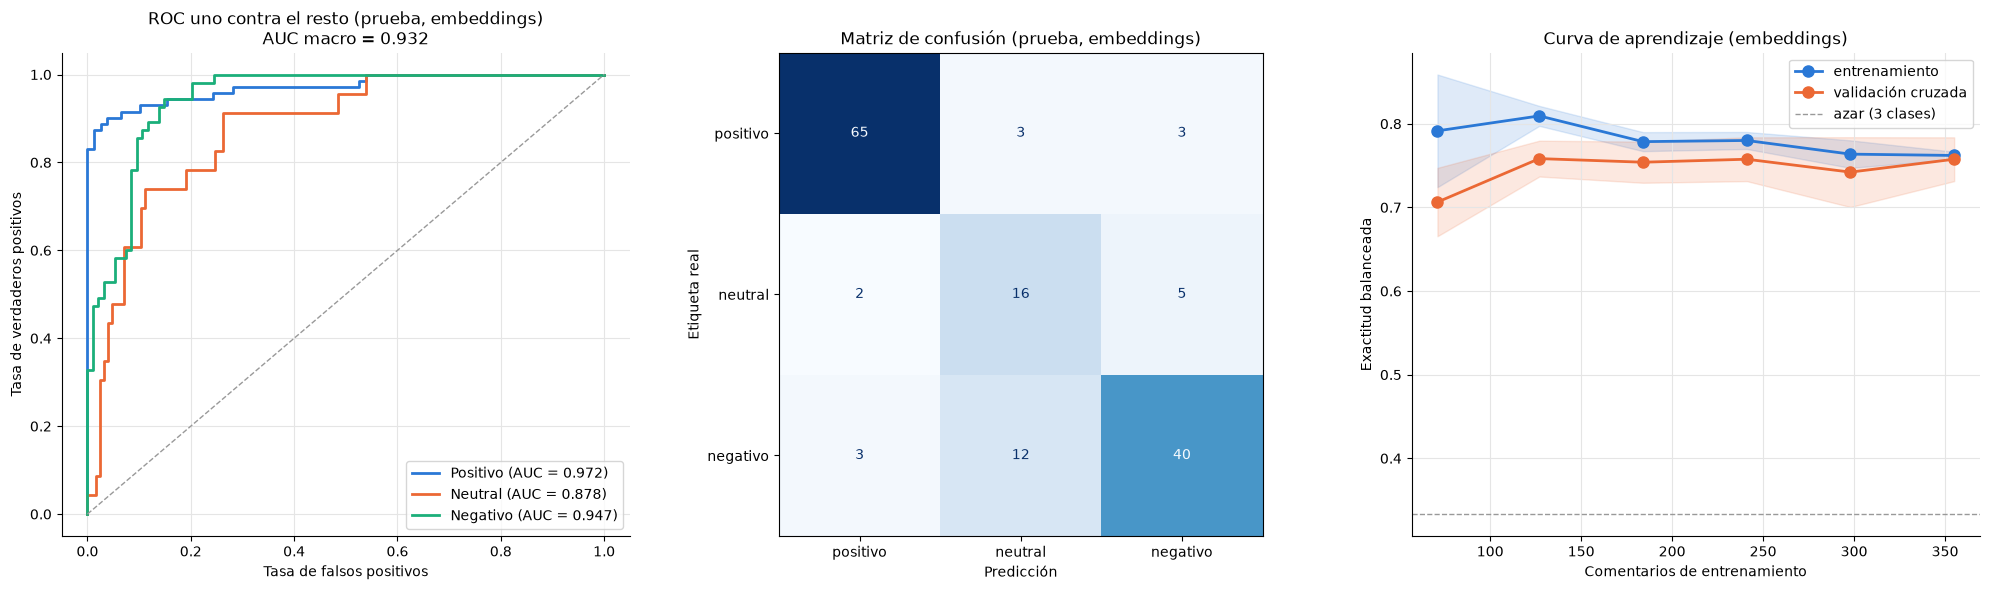

In [18]:
cv_final_emb = cross_validate(clone(candidatos_emb[NOMBRE_FINAL_EMB]), Xe_train, y_train, cv=CV, scoring=METRICAS_CV)
tabla_emb = pd.DataFrame({
    "entrenamiento": metricas(modelo_final_emb, Xe_train, y_train),
    "validación cruzada": {k: cv_final_emb[f"test_{k}"].mean() for k in METRICAS_CV},
    "prueba": metricas(modelo_final_emb, Xe_test, y_test),
    "línea base (prueba)": metricas(DummyClassifier(strategy="most_frequent").fit(Xe_train, y_train), Xe_test, y_test),
})
display(tabla_emb.round(3))
print(classification_report(y_test, modelo_final_emb.predict(Xe_test), labels=CATEGORIAS, digits=3))

fig, ejes = plt.subplots(1, 3, figsize=(20, 6))
proba_test_emb = modelo_final_emb.predict_proba(Xe_test)
for cat in CATEGORIAS:
    k = list(modelo_final_emb.classes_).index(cat)
    fpr, tpr, _ = roc_curve(y_test == cat, proba_test_emb[:, k])
    ejes[0].plot(fpr, tpr, color=COLOR_SENT[cat], linewidth=2, label=f"{cat.capitalize()} (AUC = {auc(fpr, tpr):.3f})")
ejes[0].plot([0, 1], [0, 1], color="#999999", linestyle="--", linewidth=1)
ejes[0].set_xlabel("Tasa de falsos positivos")
ejes[0].set_ylabel("Tasa de verdaderos positivos")
ejes[0].legend(loc="lower right")
ejes[0].set_title(f"ROC uno contra el resto (prueba, embeddings)\nAUC macro = {tabla_emb.loc['roc_auc_ovr', 'prueba']:.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, modelo_final_emb.predict(Xe_test), labels=CATEGORIAS, cmap="Blues",
                                        colorbar=False, ax=ejes[1])
ejes[1].set_title("Matriz de confusión (prueba, embeddings)")
ejes[1].set_xlabel("Predicción")
ejes[1].set_ylabel("Etiqueta real")

tam, sc_train, sc_val = learning_curve(clone(candidatos_emb[NOMBRE_FINAL_EMB]), Xe_train, y_train, cv=CV,
                                       scoring="balanced_accuracy", train_sizes=np.linspace(0.2, 1.0, 6))
for sc, etiqueta, color in [(sc_train, "entrenamiento", "#2a78d6"), (sc_val, "validación cruzada", "#eb6834")]:
    ejes[2].plot(tam, sc.mean(axis=1), marker="o", markersize=8, linewidth=2, color=color, label=etiqueta)
    ejes[2].fill_between(tam, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=color, alpha=0.15)
ejes[2].axhline(1 / 3, color="#999999", linestyle="--", linewidth=1, label="azar (3 clases)")
ejes[2].set_xlabel("Comentarios de entrenamiento")
ejes[2].set_ylabel("Exactitud balanceada")
ejes[2].set_title("Curva de aprendizaje (embeddings)")
ejes[2].legend()
for eje in ejes[[0, 2]]:
    eje.grid(color="#e5e5e5", linewidth=0.8)
    eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

XAI con embeddings. Las componentes principales no tienen nombre propio, así que además de SHAP se muestran, para cada componente, los comentarios de entrenamiento con el valor más alto y más bajo: eso indica qué eje de significado captura.

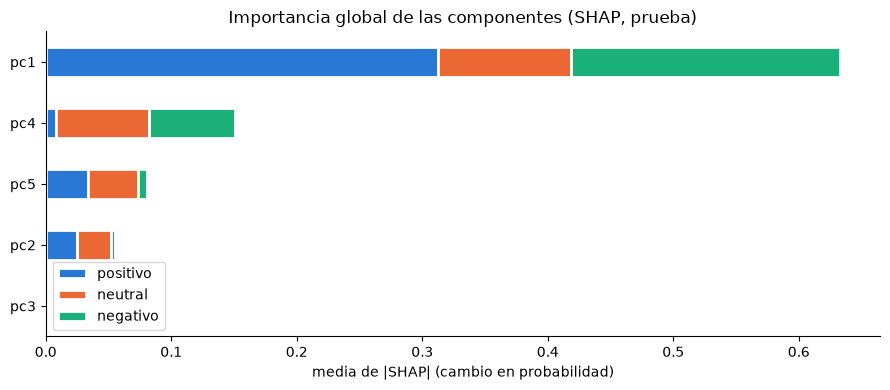

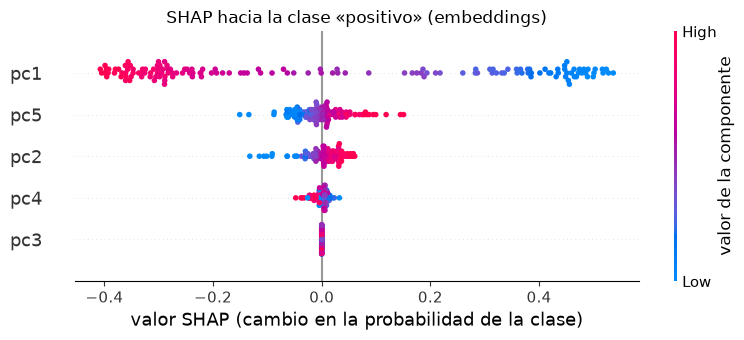

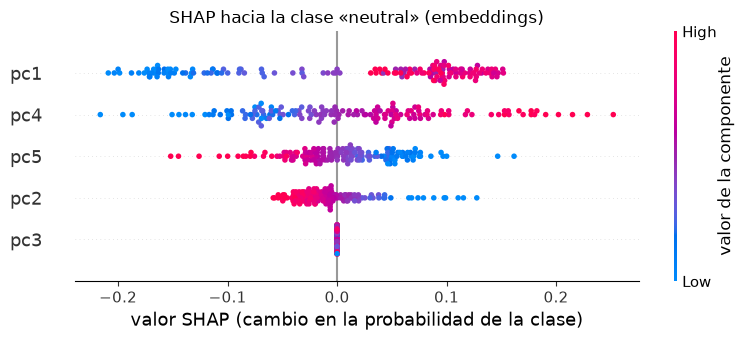

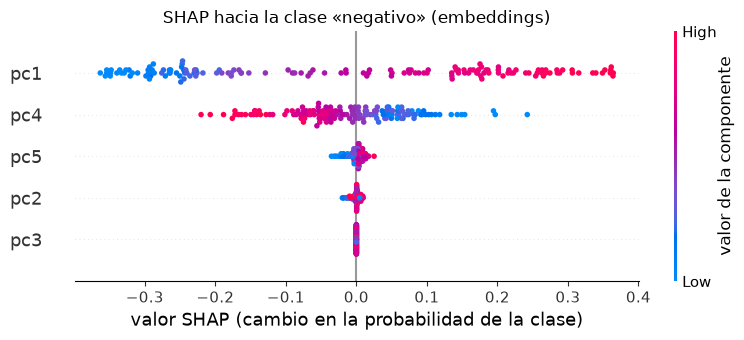

,caída media en exactitud balanceada,sd
pc1,0.341,0.044
pc4,0.119,0.032
pc2,0.005,0.019
pc3,0.000,0.000
pc5,-0.004,0.017


In [19]:
fondo_emb = shap.sample(Xe_train, 100, random_state=SEMILLA)
explicador_emb = shap.Explainer(modelo_final_emb.predict_proba, fondo_emb, algorithm="permutation", seed=SEMILLA)
valores_emb = explicador_emb(Xe_test)
clases_emb = list(modelo_final_emb.classes_)

importancia_emb = pd.DataFrame({c: np.abs(valores_emb.values[:, :, clases_emb.index(c)]).mean(axis=0) for c in CATEGORIAS},
                               index=COMPONENTES)
importancia_emb = importancia_emb.loc[importancia_emb.sum(axis=1).sort_values().index]
fig, eje = plt.subplots(figsize=(9, 4))
importancia_emb.plot.barh(stacked=True, color=[COLOR_SENT[c] for c in CATEGORIAS], edgecolor="white", linewidth=2, ax=eje)
eje.set_xlabel("media de |SHAP| (cambio en probabilidad)")
eje.set_title("Importancia global de las componentes (SHAP, prueba)")
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for c in CATEGORIAS:
    shap.plots.beeswarm(valores_emb[:, :, clases_emb.index(c)], max_display=5, show=False)
    plt.title(f"SHAP hacia la clase «{c}» (embeddings)")
    plt.xlabel("valor SHAP (cambio en la probabilidad de la clase)")
    plt.gcf().axes[-1].set_ylabel("valor de la componente")
    plt.tight_layout()
    plt.show()

perm_emb = permutation_importance(modelo_final_emb, Xe_test, y_test, scoring="balanced_accuracy", n_repeats=30, random_state=SEMILLA)
display(pd.DataFrame({"caída media en exactitud balanceada": perm_emb.importances_mean, "sd": perm_emb.importances_std},
                     index=COMPONENTES).sort_values("caída media en exactitud balanceada", ascending=False).round(3))

# qué representa cada componente: comentarios extremos en entrenamiento
extremos = []
for pc in importancia_emb.index[::-1]:
    orden = Xe_train[pc].sort_values()
    for polo, ids in [("alto", orden.index[-3:][::-1]), ("bajo", orden.index[:3])]:
        for i in ids:
            extremos.append({"componente": pc, "polo": polo, "sentimiento": y_train[i], "comentario": aux.loc[i, "text"][:160]})
pd.DataFrame(extremos).set_index(["componente", "polo"])

In [20]:
pd.DataFrame({
    "variables construidas (x1 a x9)": tabla["prueba"],
    "embeddings Gemma + PCA (5)": tabla_emb["prueba"],
}).round(3).rename_axis(f"prueba ({len(y_test)} comentarios)")

,variables construidas (x1 a x9),embeddings Gemma + PCA (5)
prueba (149 comentarios),,
exactitud,0.577,0.812
exactitud_balanceada,0.585,0.779
f1_macro,0.554,0.764
roc_auc_ovr,0.779,0.932


Lectura de los resultados con embeddings (cifras de esta ejecución):

- Las 5 componentes retienen el 29.4 % de la varianza de los 768 dimensiones, y aun así separan mucho mejor las clases: en el plano PC1 y PC2 los positivos quedan a la izquierda y los negativos a la derecha.
- TPOT vuelve a ganar con una regresión logística elastic-net con clases balanceadas. Supera a LDA, NearestCentroid y ExtraTrees de LazyPredict.
- Sin sobreajuste: la exactitud balanceada es 0.757 en entrenamiento, 0.758 en validación cruzada y 0.779 en prueba. ExtraTrees sí sobreajusta (1.000 en entrenamiento contra 0.703 en validación) y quedó descartado.
- Frente a las variables construidas, en prueba la exactitud balanceada sube de 0.585 a 0.779, el F1 macro de 0.554 a 0.764 y el AUC macro de 0.779 a 0.932. La clase neutral sigue siendo la más difícil (F1 0.593), sobre todo porque 12 negativos se predicen como neutrales.
- XAI: casi todo el poder predictivo está en PC1, un eje de tono que va de saludos y bendiciones con corazones (polo bajo) a quejas y reclamos con groserías (polo alto). PC4 aporta en segundo lugar y separa los comentarios hechos solo de emojis de los que son solo texto, como consignas cortas en mayúsculas. PC2, PC3 y PC5 casi no influyen en la predicción.

In [21]:
import joblib

# exporta el modelo ganador para el observatorio mañanero (observatorio/app.py)
RUTA_MODELO = RAIZ / "data" / "observatorio" / "modelo" / "sentimiento_gemma_pca_tpot.joblib"
RUTA_MODELO.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({
    "modelo_embeddings": MODELO_EMB,
    "prefijo": "task: classification | query: ",
    "pca": pca,
    "clasificador": modelo_final_emb,
    "clases": list(modelo_final_emb.classes_),
    "metricas_prueba": tabla_emb["prueba"].round(4).to_dict(),
    "pipeline": str(modelo_final_emb),
}, RUTA_MODELO)
print("modelo exportado en", RUTA_MODELO.relative_to(RAIZ))

modelo exportado en data/observatorio/modelo/sentimiento_gemma_pca_tpot.joblib
